    gid  pop2009  county          subcounty                    ward  \
0   241  17431.0  ISIOLO  Isiolo Sub County                  WABERA   
1  1455  18755.0  Migori   Rongo Sub County    North Kamagambo Ward   
2  1456  27756.0  Migori   Rongo Sub County  Central Kamagambo Ward   
3  1457  27179.0  Migori   Rongo Sub County    South Kamagambo Ward   
4  1458  22874.0  Migori  Awendo Sub County        North Sakwa Ward   

           uid        scuid         cuid  \
0  rIdiIpv9fBt  I2LYLqKU6AW  bzOfj0iwfDH   
1  QC41mItjIzF  fT37q3rXQ35  fVra3Pwta0Q   
2  M8rGveWTIMm  fT37q3rXQ35  fVra3Pwta0Q   
3  DABObbHgPMX  fT37q3rXQ35  fVra3Pwta0Q   
4  EmSsP2C6A3h  ka9Uv3Ckcbd  fVra3Pwta0Q   

                                            geometry      2023      2024  \
0  POLYGON ((37.59968 0.40029, 37.59976 0.40004, ...  0.050486  0.057221   
1  POLYGON ((34.59938 -0.65054, 34.60006 -0.65069...  0.105378  0.126769   
2  POLYGON ((34.61175 -0.73357, 34.61183 -0.73357...  0.098395  0.116371   
3  P

<Figure size 1000x600 with 0 Axes>

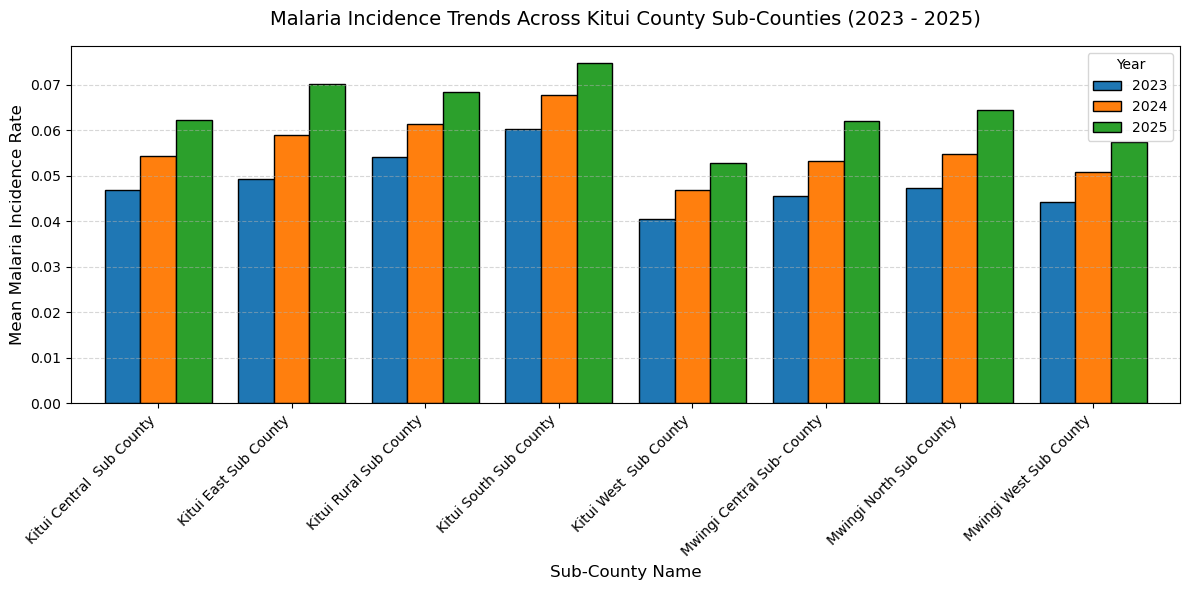

In [8]:
import os
import re
import glob
import geopandas as gpd
import numpy as np
import pandas as pd
from rasterstats import zonal_stats
import matplotlib.pyplot as plt

kenya_ward_path= r"D:\Public health\kenya_wards\kenya_wards.shp"
malaria_folder= r"D:\Public health\kenya_malaria23_24_25"

gdf= gpd.read_file(kenya_ward_path)
patterns= os.path.join(malaria_folder, 
                      "*.tiff"
                      )
raster_files= sorted(glob.glob(patterns))

for raster_path in raster_files:
    file_name= os.path.basename(raster_path)
    clean_name = file_name.replace(".tiff", "")
    year = clean_name[-4:]
    stats=zonal_stats(gdf, 
    raster_path, 
    stats="mean")
    gdf[year] = [x.get("mean") for x in stats]

final_df=pd.DataFrame(gdf).copy()
print(final_df.head())

kitui_data = final_df.loc[
    final_df["county"].str.lower() == "kitui"
    ].copy()

kitui_subcounties = kitui_data.groupby("subcounty")[
    ["2023", "2024", "2025"]
    ].mean()

plt.figure(
    figsize=(10, 6)
)

ax = kitui_subcounties.plot(
    kind="bar", 
    figsize=(12, 6), 
    width=0.8, 
    edgecolor="black"
)

plt.title("Malaria Incidence Trends Across Kitui County Sub-Counties (2023 - 2025)", 
          fontsize=14, 
          pad=15
         )
plt.xlabel("Sub-County Name", 
           fontsize=12
          )
plt.ylabel("Mean Malaria Incidence Rate", 
           fontsize=12
          )

plt.xticks(rotation=45, 
           ha="right"
          ) 

plt.grid(axis="y", 
         linestyle="--", 
         alpha=0.5)

plt.legend(title="Year", 
           frameon=True
          )

plt.tight_layout()
plt.show()




    